## **Mount Drive**

In [1]:
# Import the required libraries.
from google.colab import drive
import os
import time

# Mount Google Drive with automatic retries if mounting fails.
def mount_drive():
    for attempt in range(3):
        try:
            try:
                drive.flush_and_unmount()
            except:
                pass

            drive.mount('/content/drive', force_remount=True)
            time.sleep(5)

            # Verify that Google Drive is accessible.
            os.listdir('/content/drive/MyDrive')

            print(f"Drive mounted (attempt {attempt + 1})")
            return True

        except Exception as e:
            print(f"Attempt {attempt + 1} failed: {e}")
            time.sleep(10)

    return False

# Mount Google Drive.
mount_drive()

# Define the project directory.
PROJECT = '/content/drive/MyDrive/fake_image_detection'

print("Ready")

Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive
Drive mounted (attempt 1)
Ready


## **Install libraries**

In [2]:
# Install external dependency for reading image metadata.
!pip install -q exifread

# Import libraries for data handling, visualization, and ML.
import exifread
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    f1_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

from PIL import Image
from tqdm import tqdm

import os
import random
import json
import shutil
import time

print("Libraries imported")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.7/59.7 kB 2.4 MB/s eta 0:00:00
Libraries imported


## **Define paths**

In [3]:
# Define dataset and output paths

# Google Drive project directories.
FRAMES_REAL = f"{PROJECT}/data/frames/real"
FRAMES_FAKE = f"{PROJECT}/data/frames/fake"
SPLIT_DIR = f"{PROJECT}/data/splits"
BALANCED_DIR = f"{PROJECT}/data/balanced"
PREDICTIONS_DIR = f"{PROJECT}/predictions"

# Local working directories (faster I/O during runtime).
LOCAL_FRAMES_REAL = "/content/frames/real"
LOCAL_FRAMES_FAKE = "/content/frames/fake"

# Create required local directories if they do not exist.
os.makedirs(LOCAL_FRAMES_REAL, exist_ok=True)
os.makedirs(LOCAL_FRAMES_FAKE, exist_ok=True)
os.makedirs(PREDICTIONS_DIR, exist_ok=True)

print("Paths initialised")

Paths initialised


## **Copy frames to local**

In [4]:
# Copy (balanced) frames to local disk"""

# Load balanced file lists.
with open(f"{BALANCED_DIR}/real_files.txt") as f:
    real_balanced_names = [line.strip() for line in f if line.strip()]

with open(f"{BALANCED_DIR}/fake_files.txt") as f:
    fake_balanced_names = [line.strip() for line in f if line.strip()]

# Copy only the balanced dataset to local storage.
def copy_balanced(src_dir, dst_dir, filenames, label):

    # Skip files that have already been copied.
    already = set(os.listdir(dst_dir))
    to_copy = [f for f in filenames if f not in already]

    print(
        f"\n{label}: {len(filenames)} required | "
        f"{len(already)} already local | "
        f"{len(to_copy)} to copy"
    )

    if not to_copy:
        print("Already copied locally")
        return

    copied, failed = 0, 0

    # Copy each missing file.
    for fname in tqdm(to_copy, desc=f"Copying {label}"):
        try:
            shutil.copy(
                os.path.join(src_dir, fname),
                os.path.join(dst_dir, fname)
            )
            copied += 1
        except Exception:
            failed += 1

    print(f"Completed: copied {copied}, failed {failed}")
    print(f"Total local files: {len(os.listdir(dst_dir))}")

# Copy balanced real and fake images.
copy_balanced(
    FRAMES_REAL,
    LOCAL_FRAMES_REAL,
    real_balanced_names,
    "Real frames"
)

copy_balanced(
    FRAMES_FAKE,
    LOCAL_FRAMES_FAKE,
    fake_balanced_names,
    "Fake frames"
)


Real frames: 2064 required | 0 already local | 2064 to copy


Copying Real frames: 100%|██████████| 2064/2064 [10:48<00:00,  3.18it/s]


Completed: copied 2064, failed 0
Total local files: 2064

Fake frames: 2064 required | 0 already local | 2064 to copy


Copying Fake frames: 100%|██████████| 2064/2064 [18:29<00:00,  1.86it/s]

Completed: copied 2063, failed 1
Total local files: 2063


## **EXIF metadata parser**

In [5]:
# EXIF metadata extraction and suspiciousness scoring

# List of known image editing / generation tools.
EDITING_SOFTWARE = [
    "photoshop", "gimp", "lightroom", "paint", "affinity",
    "pixelmator", "capture one", "darktable", "rawtherapee",
    "stable diffusion", "midjourney", "dall-e", "python"
]

# EXIF fields expected in a natural (untampered) image.
EXPECTED_FIELDS = [
    "Image Make",
    "Image Model",
    "EXIF DateTimeOriginal",
    "EXIF ExposureTime",
    "EXIF ISOSpeedRatings",
    "EXIF FocalLength"
]


def extract_exif_score(img_path):
    """
    Score range:
        0.0 = no suspicion
        1.0 = highly suspicious

    Heuristics:
        - Missing EXIF fields: +0.10 each (capped indirectly via max score)
        - Editing software detected: +0.30
        - No EXIF data: +0.50
        - Missing timestamp: +0.20
        - Camera model present: neutral signal
    """

    result = {
        "score": 0.0,
        "has_exif": False,
        "missing_fields": 0,
        "editing_software": False,
        "software_name": None,
        "has_timestamp": False,
        "has_camera_model": False,
    }

    try:
        # Read image metadata.
        with open(img_path, "rb") as f:
            tags = exifread.process_file(
                f,
                stop_tag="EXIF MakerNote",
                details=False
            )

        # If no EXIF data exists, assign high suspicion.
        if not tags:
            result["score"] = 0.50
            return result

        result["has_exif"] = True

        # Count missing expected EXIF fields.
        missing = sum(field not in tags for field in EXPECTED_FIELDS)
        result["missing_fields"] = missing
        result["score"] += missing * 0.10

        # Detect editing or generation software signatures.
        software = str(tags.get("Image Software", "")).lower()
        if any(sw in software for sw in EDITING_SOFTWARE):
            result["editing_software"] = True
            result["software_name"] = software
            result["score"] += 0.30

        # Check timestamp presence.
        if "EXIF DateTimeOriginal" in tags:
            result["has_timestamp"] = True
        else:
            result["score"] += 0.20

        # Check camera model metadata.
        if "Image Model" in tags:
            result["has_camera_model"] = True

        # Clamp score to valid range.
        result["score"] = min(result["score"], 1.0)

    except Exception:
        # If parsing fails, assume moderate suspicion.
        result["score"] = 0.50

    return result

# Status output for debugging.
print("EXIF parser defined")
print("Signals used:")
print("- Missing EXIF fields (+0.10 each)")
print("- Editing software detected (+0.30)")
print("- No EXIF data (+0.50)")
print("- Missing timestamp (+0.20)")

EXIF parser defined
Signals used:
- Missing EXIF fields (+0.10 each)
- Editing software detected (+0.30)
- No EXIF data (+0.50)
- Missing timestamp (+0.20)


## **Run metadata analysis on test set**

In [6]:
# Run EXIF analysis on balanced test set

# Load balanced file lists (kept in original order for consistency with dataset construction).
with open(f"{BALANCED_DIR}/real_files.txt") as f:
    real_balanced = [line.strip() for line in f if line.strip()]

with open(f"{BALANCED_DIR}/fake_files.txt") as f:
    fake_balanced = [line.strip() for line in f if line.strip()]

# Load test split indices.
test_indices = np.load(f"{SPLIT_DIR}/test_indices.npy").tolist()

# Reconstruct full sample list in the same order used during dataset creation.
all_samples = [(f, 0) for f in real_balanced] + [(f, 1) for f in fake_balanced]

# Ensure indices are within valid range.
max_valid = len(all_samples) - 1
test_indices = [i for i in test_indices if i <= max_valid]

# Select only test samples.
test_samples = [all_samples[i] for i in test_indices]

print(f"Running EXIF analysis on {len(test_samples)} test images...")

# Storage for results.
test_scores = []
test_labels = []
test_details = []

# Run EXIF scoring on each test image.
for img_name, label in tqdm(test_samples, desc="EXIF analysis"):

    src_dir = LOCAL_FRAMES_REAL if label == 0 else LOCAL_FRAMES_FAKE
    img_path = os.path.join(src_dir, img_name)

    if not os.path.exists(img_path):
        continue

    result = extract_exif_score(img_path)

    test_scores.append(result["score"])
    test_labels.append(label)

    test_details.append({
        "filename": img_name,
        "label": label,
        "score": result["score"],
        "has_exif": result["has_exif"],
        "missing_fields": result["missing_fields"],
        "editing_software": result["editing_software"],
        "software_name": result["software_name"],
        "has_timestamp": result["has_timestamp"],
        "has_camera_model": result["has_camera_model"],
    })

# Check to ensure all test samples were processed
print(f"Samples requested: {len(test_samples)}")
print(f"Samples processed: {len(test_scores)}")

if len(test_scores) != len(test_samples):
    print("Mismatch detected: some files are missing on disk")

# Classification threshold for EXIF-based fake detection.
THRESHOLD = 0.4
test_preds = [1 if s > THRESHOLD else 0 for s in test_scores]

# Evaluation summary.
print(f"\n MODULE 3 RESULTS (threshold={THRESHOLD})")
print(classification_report(test_labels, test_preds, target_names=["Real", "Fake"]))
print(f"AUC-ROC: {roc_auc_score(test_labels, test_scores):.4f}")

# Save detailed results.
details_df = pd.DataFrame(test_details)
details_df.to_csv(f"{PROJECT}/outputs/m3_exif_details.csv", index=False)

Running EXIF analysis on 620 test images...


EXIF analysis: 100%|██████████| 620/620 [00:00<00:00, 4908.28it/s]

Samples requested: 620
Samples processed: 620

 MODULE 3 RESULTS (threshold=0.4)
              precision    recall  f1-score   support

        Real       0.08      0.02      0.03       322
        Fake       0.43      0.81      0.56       298

    accuracy                           0.40       620
   macro avg       0.26      0.41      0.29       620
weighted avg       0.25      0.40      0.28       620

AUC-ROC: 0.8091


## **Visualise EXIF findings**

/tmp/ipykernel_382/534423282.py:50: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1][0].boxplot(


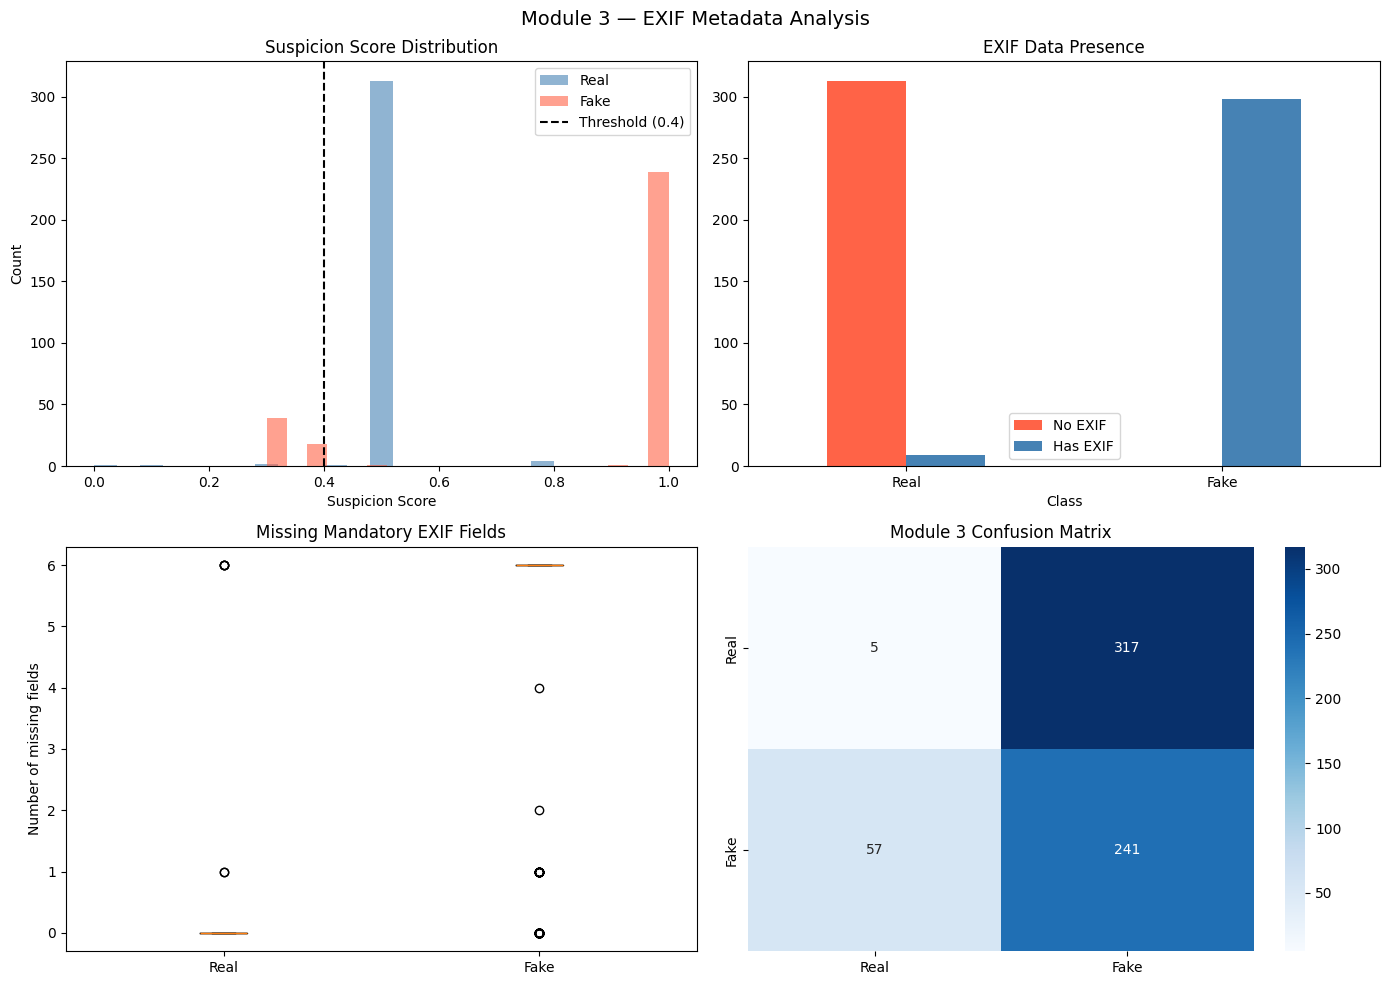

In [7]:
# Visualise EXIF metadata findings

# Convert results into DataFrame for analysis.
details_df = pd.DataFrame(test_details)

# Create figure layout.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Module 3 — EXIF Metadata Analysis", fontsize=14)

# Score distribution
real_scores = details_df[details_df["label"] == 0]["score"]
fake_scores = details_df[details_df["label"] == 1]["score"]

axes[0][0].hist(real_scores, bins=20, alpha=0.6, color="steelblue", label="Real")
axes[0][0].hist(fake_scores, bins=20, alpha=0.6, color="tomato", label="Fake")
axes[0][0].axvline(
    x=THRESHOLD,
    color="black",
    linestyle="--",
    label=f"Threshold ({THRESHOLD})"
)
axes[0][0].set_title("Suspicion Score Distribution")
axes[0][0].set_xlabel("Suspicion Score")
axes[0][0].set_ylabel("Count")
axes[0][0].legend()

# EXIF presence
exif_counts = (
    details_df
    .groupby(["label", "has_exif"])
    .size()
    .unstack(fill_value=0)
)

exif_counts.index = ["Real", "Fake"]
exif_counts.columns = ["No EXIF", "Has EXIF"]

exif_counts.plot(
    kind="bar",
    ax=axes[0][1],
    color=["tomato", "steelblue"]
)

axes[0][1].set_title("EXIF Data Presence")
axes[0][1].set_xlabel("Class")
axes[0][1].legend()
axes[0][1].tick_params(axis="x", rotation=0)

# Missing fields
axes[1][0].boxplot(
    [
        details_df[details_df["label"] == 0]["missing_fields"],
        details_df[details_df["label"] == 1]["missing_fields"],
    ],
    labels=["Real", "Fake"]
)

axes[1][0].set_title("Missing Mandatory EXIF Fields")
axes[1][0].set_ylabel("Number of missing fields")

# Confusion matrix
cm = confusion_matrix(test_labels, test_preds)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Real", "Fake"],
    yticklabels=["Real", "Fake"],
    ax=axes[1][1]
)

axes[1][1].set_title("Module 3 Confusion Matrix")

# Final layout and save.
plt.tight_layout()
plt.savefig(f"{PROJECT}/outputs/m3_analysis.png", dpi=150)
plt.show()

## **Save Module 3 predictions**

In [8]:
# Save prediction scores, predicted labels, and ground-truth labels.
np.save(
    f"{PREDICTIONS_DIR}/m3_test_scores.npy",
    np.array(test_scores)
)
np.save(
    f"{PREDICTIONS_DIR}/m3_test_preds.npy",
    np.array(test_preds)
)
np.save(
    f"{PREDICTIONS_DIR}/m3_test_labels.npy",
    np.array(test_labels)
)
# Confirm successful export.
print("=== Module 3 Predictions Saved ===")
print(f"Test scores: {len(test_scores)}")
print(f"Test predictions: {len(test_preds)}")
print(f"Test labels: {len(test_labels)}")
print("Saved successfully for fusion classifier.")

=== Module 3 Predictions Saved ===
Test scores: 620
Test predictions: 620
Test labels: 620
Saved successfully for fusion classifier.


##

## **FUSION CLASSIFIER**

## **Load all module predictions**

In [9]:
# Load Module 1 predictions.
m1_probs = np.load(f"{PREDICTIONS_DIR}/m1_test_probs.npy")
m1_preds = np.load(f"{PREDICTIONS_DIR}/m1_test_preds.npy")
m1_labels = np.load(f"{PREDICTIONS_DIR}/m1_test_labels.npy")

# Load Module 2 predictions.
m2_probs = np.load(f"{PREDICTIONS_DIR}/m2_test_probs.npy")
m2_preds = np.load(f"{PREDICTIONS_DIR}/m2_test_preds.npy")
m2_labels = np.load(f"{PREDICTIONS_DIR}/m2_test_labels.npy")

# Load Module 3 predictions.
m3_scores = np.load(f"{PREDICTIONS_DIR}/m3_test_scores.npy")
m3_preds = np.load(f"{PREDICTIONS_DIR}/m3_test_preds.npy")
m3_labels = np.load(f"{PREDICTIONS_DIR}/m3_test_labels.npy")

# Display array sizes before verification.
print("...Array lengths before alignment check...")
print(f"Module 1: {len(m1_labels)}")
print(f"Module 2: {len(m2_labels)}")
print(f"Module 3: {len(m3_labels)}")

# Verify that all modules use the same test labels.
assert np.array_equal(
    m1_labels,
    m2_labels
), "Module 1 and Module 2 test labels do not match."

assert np.array_equal(
    m1_labels,
    m3_labels
), ("Module 1 and Module 3 test labels do not match. ")

# Use the verified labels as ground truth.
true_labels = m1_labels

# Display summary.
print("\n...Predictions Loaded...")
print(f"Module 1 (ResNet-50): {len(m1_probs)} predictions")
print(f"Module 2 (EfficientNet-B0): {len(m2_probs)} predictions")
print(f"Module 3 (EXIF): {len(m3_scores)} scores")
print(f"Ground-truth labels: {len(true_labels)}")
print("All labels verified successfully.")

...Array lengths before alignment check...
Module 1: 620
Module 2: 620
Module 3: 620

...Predictions Loaded...
Module 1 (ResNet-50): 620 predictions
Module 2 (EfficientNet-B0): 620 predictions
Module 3 (EXIF): 620 scores
Ground-truth labels: 620
All labels verified successfully.


## **Individual module performance**

In [10]:
# Compare individual module performance

print("... Individual Module Performance ...\n")

# Store predictions and probability scores for each module.
modules = {
    "Module 1 - ResNet-50 (Spatial)": (m1_preds, m1_probs),
    "Module 2 - EfficientNet-B0 (Frequency)": (m2_preds, m2_probs),
    "Module 3 - EXIF Metadata": (m3_preds, m3_scores),
}

results = {}

# Evaluate each module individually.
for name, (preds, probs) in modules.items():
    acc = 100.0 * np.mean(preds == true_labels)
    auc = roc_auc_score(true_labels, probs)
    f1 = f1_score(true_labels, preds, average="weighted")

    results[name] = {
        "Accuracy": acc,
        "AUC": auc,
        "F1": f1,
    }

    print(name)
    print(f"Accuracy : {acc:.2f}%")
    print(f"AUC-ROC  : {auc:.4f}")
    print(f"F1 Score : {f1:.4f}\n")

# Create a summary table.
results_df = pd.DataFrame(results).T
print(results_df.to_string())

... Individual Module Performance ...

Module 1 - ResNet-50 (Spatial)
Accuracy : 89.03%
AUC-ROC  : 0.9481
F1 Score : 0.8903

Module 2 - EfficientNet-B0 (Frequency)
Accuracy : 87.42%
AUC-ROC  : 0.9388
F1 Score : 0.8739

Module 3 - EXIF Metadata
Accuracy : 39.68%
AUC-ROC  : 0.8091
F1 Score : 0.2842

                                         Accuracy       AUC        F1
Module 1 - ResNet-50 (Spatial)          89.032258  0.948060  0.890291
Module 2 - EfficientNet-B0 (Frequency)  87.419355  0.938826  0.873905
Module 3 - EXIF Metadata                39.677419  0.809116  0.284169


## **Build fusion classifier**

In [11]:
# Train logistic regression fusion classifier with hyperparameter tuning

# Create the feature matrix by combining outputs from all modules.
X = np.column_stack([
    m1_probs,
    m2_probs,
    m3_scores,
])

# Ground-truth labels.
y = true_labels

print(f"Fusion feature matrix shape: {X.shape}")
print("Feature 1: Module 1 fake probability")
print("Feature 2: Module 2 fake probability")
print("Feature 3: Module 3 suspicion score")

# Standardise features before model training.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Define the hyperparameter search space.
param_grid = {
    "C": [0.01, 0.1, 1.0, 10.0, 100.0]
}

# Perform grid search to find the optimal regularisation strength.
grid_search = GridSearchCV(
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid_search.fit(X_scaled, y)

# Display cross-validation results for each hyperparameter.
print("\n=== Hyperparameter Search Results ===")

for mean, std, params in zip(
    grid_search.cv_results_["mean_test_score"],
    grid_search.cv_results_["std_test_score"],
    grid_search.cv_results_["params"]
):
    print(f"C={params['C']:<6} AUC={mean:.4f} ± {std:.4f}")

print(f"\nBest C: {grid_search.best_params_['C']}")
print(f"Best Cross-Validation AUC: {grid_search.best_score_:.4f}")

# Use the best-performing model for subsequent analysis.
fusion_model = grid_search.best_estimator_

# Evaluate the selected model using 5-fold cross-validation.
cv_scores = cross_val_score(
    fusion_model,
    X_scaled,
    y,
    cv=5,
    scoring="roc_auc"
)

print("\n5-Fold Cross-Validation AUC (Best Model)")
print(f"Scores: {cv_scores.round(4)}")
print(f"Mean: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

# Display the learned feature weights.
coef = fusion_model.coef_[0]

print("\nLogistic regression feature weights")
print(f"Module 1 (Spatial CNN): {coef[0]:.4f}")
print(f"Module 2 (Frequency CNN): {coef[1]:.4f}")
print(f"Module 3 (EXIF Metadata): {coef[2]:.4f}")

print("\nLarger coefficients indicate a stronger contribution to fake image detection.")

Fusion feature matrix shape: (620, 3)
Feature 1: Module 1 fake probability
Feature 2: Module 2 fake probability
Feature 3: Module 3 suspicion score

=== Hyperparameter Search Results ===
C=0.01   AUC=0.9828 ± 0.0072
C=0.1    AUC=0.9831 ± 0.0071
C=1.0    AUC=0.9831 ± 0.0074
C=10.0   AUC=0.9831 ± 0.0073
C=100.0  AUC=0.9831 ± 0.0073

Best C: 1.0
Best Cross-Validation AUC: 0.9831

5-Fold Cross-Validation AUC (Best Model)
Scores: [0.9815 0.9898 0.9906 0.9836 0.9701]
Mean: 0.9831 ± 0.0074

Logistic regression feature weights
Module 1 (Spatial CNN): 1.9155
Module 2 (Frequency CNN): 1.3582
Module 3 (EXIF Metadata): 1.5777

Larger coefficients indicate a stronger contribution to fake image detection.


## **Fusion evaluation**

...Fusion Classifier Results...
              precision    recall  f1-score   support

        Real       0.98      0.91      0.94       322
        Fake       0.91      0.98      0.94       298

    accuracy                           0.94       620
   macro avg       0.95      0.95      0.94       620
weighted avg       0.95      0.94      0.94       620

AUC-ROC: 0.9829
F1 Score: 0.9435
Accuracy: 94.35%


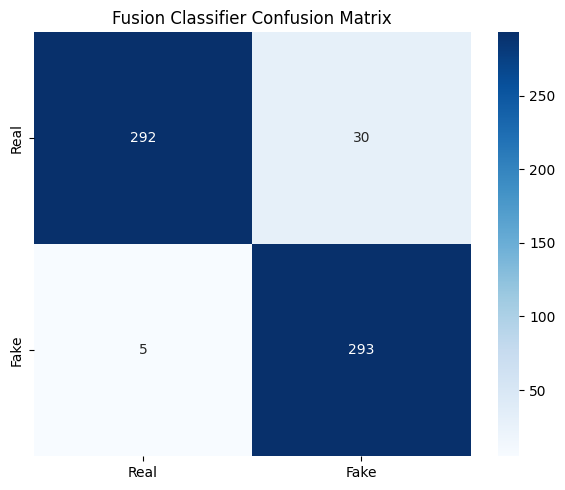

In [12]:
# Evaluate fusion classifier

# Generate prediction probabilities and class predictions.
fusion_probs = fusion_model.predict_proba(X_scaled)[:, 1]
fusion_preds = fusion_model.predict(X_scaled)

# Calculate evaluation metrics.
fusion_acc = 100.0 * np.mean(fusion_preds == y)
fusion_auc = roc_auc_score(y, fusion_probs)
fusion_f1 = f1_score(y, fusion_preds, average="weighted")

# Display classification results.
print("...Fusion Classifier Results...")
print(
    classification_report(
        y,
        fusion_preds,
        target_names=["Real", "Fake"]
    )
)

print(f"AUC-ROC: {fusion_auc:.4f}")
print(f"F1 Score: {fusion_f1:.4f}")
print(f"Accuracy: {fusion_acc:.2f}%")

# Compute and visualise the confusion matrix.
cm = confusion_matrix(y, fusion_preds)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Real", "Fake"],
    yticklabels=["Real", "Fake"]
)

plt.title("Fusion Classifier Confusion Matrix")
plt.tight_layout()
plt.savefig(f"{PROJECT}/outputs/fusion_confusion_matrix.png", dpi=150)
plt.show()

## **Full comparison and ablation study**

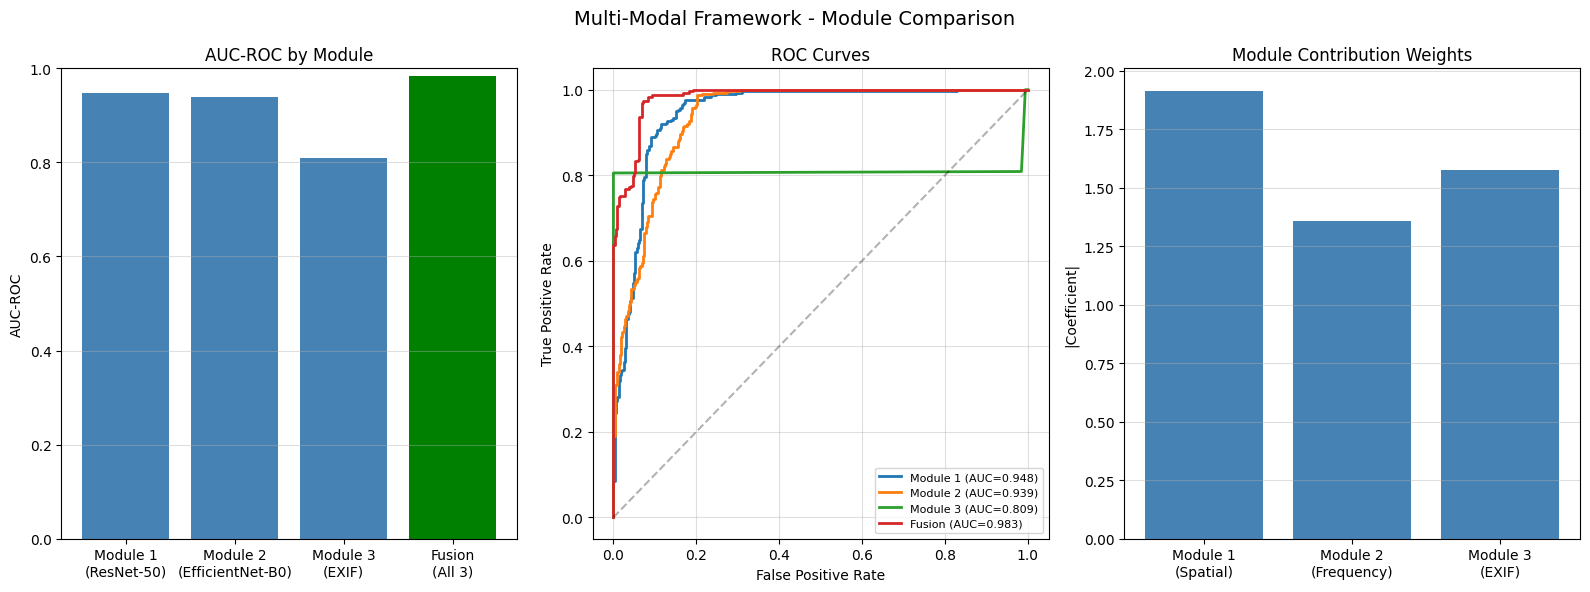


---Module Contribution Analysis (Ablation Study)---
Evaluating the impact of removing each module.

All 3 modules                   : AUC=0.9829 (Drop=+0.0000)
Without Module 1 (Spatial)      : AUC=0.9624 (Drop=+0.0206)
Without Module 2 (Frequency)    : AUC=0.9803 (Drop=+0.0026)
Without Module 3 (EXIF)         : AUC=0.9539 (Drop=+0.0290)

The largest performance drop indicates the most influential module.


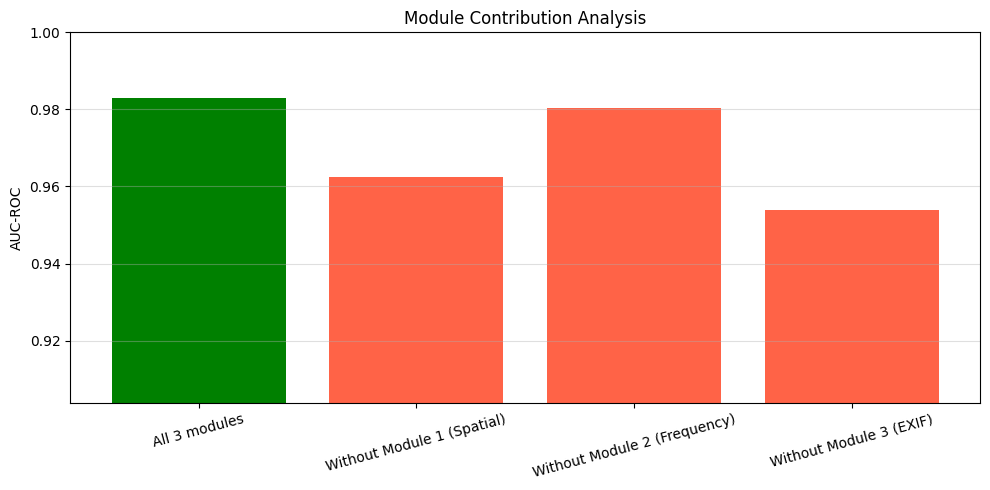

In [13]:
# Compare module performance and analyse feature contributions

# Create comparison figure.
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle("Multi-Modal Framework - Module Comparison", fontsize=14)

# ... AUC comparison ...
all_results = {
    "Module 1\n(ResNet-50)": roc_auc_score(true_labels, m1_probs),
    "Module 2\n(EfficientNet-B0)": roc_auc_score(true_labels, m2_probs),
    "Module 3\n(EXIF)": roc_auc_score(true_labels, m3_scores),
    "Fusion\n(All 3)": fusion_auc,
}

colours = ["steelblue", "steelblue", "steelblue", "green"]

axes[0].bar(all_results.keys(), all_results.values(), color=colours)
axes[0].set_title("AUC-ROC by Module")
axes[0].set_ylabel("AUC-ROC")
axes[0].set_ylim([0, 1])
axes[0].grid(True, axis="y", alpha=0.4)

# ... ROC curves ...
for name, probs in [
    ("Module 1", m1_probs),
    ("Module 2", m2_probs),
    ("Module 3", m3_scores),
    ("Fusion", fusion_probs),
]:
    fpr, tpr, _ = roc_curve(true_labels, probs)
    auc = roc_auc_score(true_labels, probs)

    axes[1].plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.3f})",
        lw=2
    )

axes[1].plot([0, 1], [0, 1], "k--", alpha=0.3)
axes[1].set_title("ROC Curves")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.4)

# ... Feature weights ...
weight_names = [
    "Module 1\n(Spatial)",
    "Module 2\n(Frequency)",
    "Module 3\n(EXIF)"
]

weight_values = np.abs(fusion_model.coef_[0])

axes[2].bar(
    weight_names,
    weight_values,
    color=["steelblue", "steelblue", "steelblue"]
)

axes[2].set_title("Module Contribution Weights")
axes[2].set_ylabel("|Coefficient|")
axes[2].grid(True, axis="y", alpha=0.4)

# Save comparison figure.
plt.tight_layout()
plt.savefig(f"{PROJECT}/outputs/fusion_comparison.png", dpi=150)
plt.show()

# ... Ablation study ...
print("\n---Module Contribution Analysis (Ablation Study)---")
print("Evaluating the impact of removing each module.\n")

ablation_results = {}
auc_all = roc_auc_score(y, fusion_probs)
ablation_results["All 3 modules"] = auc_all

# Remove Module 1.
X_no_m1 = scaler.transform(
    np.column_stack([
        np.zeros_like(m1_probs),
        m2_probs,
        m3_scores
    ])
)

auc_no_m1 = roc_auc_score(
    y,
    LogisticRegression(
        C=1.0,
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ).fit(X_no_m1, y).predict_proba(X_no_m1)[:, 1]
)

# Remove Module 2.
X_no_m2 = scaler.transform(
    np.column_stack([
        m1_probs,
        np.zeros_like(m2_probs),
        m3_scores
    ])
)

auc_no_m2 = roc_auc_score(
    y,
    LogisticRegression(
        C=1.0,
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ).fit(X_no_m2, y).predict_proba(X_no_m2)[:, 1]
)

# Remove Module 3.
X_no_m3 = scaler.transform(
    np.column_stack([
        m1_probs,
        m2_probs,
        np.zeros_like(m3_scores)
    ])
)

auc_no_m3 = roc_auc_score(
    y,
    LogisticRegression(
        C=1.0,
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ).fit(X_no_m3, y).predict_proba(X_no_m3)[:, 1]
)

ablation_results["Without Module 1 (Spatial)"] = auc_no_m1
ablation_results["Without Module 2 (Frequency)"] = auc_no_m2
ablation_results["Without Module 3 (EXIF)"] = auc_no_m3

# Display ablation results.
for name, auc in ablation_results.items():
    drop = auc_all - auc
    print(f"{name:<32}: AUC={auc:.4f} (Drop={drop:+.4f})")

print("\nThe largest performance drop indicates the most influential module.")

# Plot ablation study results.
fig, ax = plt.subplots(figsize=(10, 5))

colours = ["green"] + ["tomato"] * 3

ax.bar(
    ablation_results.keys(),
    ablation_results.values(),
    color=colours
)

ax.set_ylabel("AUC-ROC")
ax.set_title("Module Contribution Analysis")
ax.set_ylim([min(ablation_results.values()) - 0.05, 1.0])
ax.grid(True, axis="y", alpha=0.4)

plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(f"{PROJECT}/outputs/ablation_study.png", dpi=150)
plt.show()

## **Generate forensic report**

In [14]:
# Generate interpretable forensic output report

# Load the test split.
test_indices = np.load(f"{SPLIT_DIR}/test_indices.npy").tolist()

# Load balanced file lists in their original order.
with open(f"{BALANCED_DIR}/real_files.txt") as f:
    real_balanced = [line.strip() for line in f if line.strip()]

with open(f"{BALANCED_DIR}/fake_files.txt") as f:
    fake_balanced = [line.strip() for line in f if line.strip()]

# Reconstruct the complete sample list.
all_samples = (
    [(f, 0) for f in real_balanced] +
    [(f, 1) for f in fake_balanced]
)

# Keep only valid test indices.
max_valid = len(all_samples) - 1
test_indices = [i for i in test_indices if i <= max_valid]
test_samples = [all_samples[i] for i in test_indices]

# Randomly select correctly classified samples.
correct_idx = [
    i for i, (pred, true) in enumerate(zip(fusion_preds, true_labels))
    if pred == true
]

sample_idx = random.sample(
    correct_idx[:100],
    min(4, len(correct_idx))
)

print("--- Forensic Evidence Report ---\n")

# Display evidence supporting each prediction.
for idx in sample_idx:

    img_name, true_label = test_samples[idx]
    pred_label = fusion_preds[idx]
    pred_prob = fusion_probs[idx]

    print(f"Image: {img_name}")
    print(f"Ground Truth: {'REAL' if true_label == 0 else 'FAKE'}")
    print(
        f"Prediction: {'REAL' if pred_label == 0 else 'FAKE'} "
        f"(Confidence: {pred_prob * 100:.1f}%)"
    )

    print("Supporting Evidence")
    print(
        f"  Module 1 (Pixel artefacts): "
        f"{m1_probs[idx] * 100:.1f}% fake probability"
    )
    print(
        f"  Module 2 (Frequency patterns): "
        f"{m2_probs[idx] * 100:.1f}% fake probability"
    )
    print(
        f"  Module 3 (EXIF metadata): "
        f"{m3_scores[idx]:.2f} / 1.00 suspicion score"
    )
    print(
        f"  Fusion decision: "
        f"{'FAKE' if pred_label == 1 else 'REAL'} "
        f"({pred_prob * 100:.1f}% confidence)"
    )

--- Forensic Evidence Report ---

Image: id36_0001_frame0120.jpg
Ground Truth: REAL
Prediction: REAL (Confidence: 0.5%)
Supporting Evidence
  Module 1 (Pixel artefacts): 0.0% fake probability
  Module 2 (Frequency patterns): 0.1% fake probability
  Module 3 (EXIF metadata): 0.50 / 1.00 suspicion score
  Fusion decision: REAL (0.5% confidence)
Image: Tp_S_NRN_S_O_ani10103_ani10103_10634.jpg
Ground Truth: FAKE
Prediction: FAKE (Confidence: 98.8%)
Supporting Evidence
  Module 1 (Pixel artefacts): 90.4% fake probability
  Module 2 (Frequency patterns): 99.9% fake probability
  Module 3 (EXIF metadata): 1.00 / 1.00 suspicion score
  Fusion decision: FAKE (98.8% confidence)
Image: Au_cha_30301.jpg
Ground Truth: REAL
Prediction: REAL (Confidence: 44.3%)
Supporting Evidence
  Module 1 (Pixel artefacts): 61.2% fake probability
  Module 2 (Frequency patterns): 86.1% fake probability
  Module 3 (EXIF metadata): 0.50 / 1.00 suspicion score
  Fusion decision: REAL (44.3% confidence)
Image: 00047_fr

## **Save final summary**

In [15]:
# Store the final performance metrics and fusion model weights.
summary = {
    "Module 1 AUC": roc_auc_score(true_labels, m1_probs),
    "Module 2 AUC": roc_auc_score(true_labels, m2_probs),
    "Module 3 AUC": roc_auc_score(true_labels, m3_scores),
    "Fusion AUC": fusion_auc,
    "Fusion Accuracy": fusion_acc,
    "Fusion F1": fusion_f1,
    "CV AUC Mean": cv_scores.mean(),
    "CV AUC Std": cv_scores.std(),
    "Module 1 Weight": float(fusion_model.coef_[0][0]),
    "Module 2 Weight": float(fusion_model.coef_[0][1]),
    "Module 3 Weight": float(fusion_model.coef_[0][2]),
}

# Save the summary as a CSV file.
summary_df = pd.DataFrame([summary])
summary_df.to_csv(
    f"{PROJECT}/outputs/framework_summary.csv",
    index=False
)

# Display the summary.
print("... Final Framework Summary ...")

for key, value in summary.items():
    print(f"{key:<20}: {value:.4f}")

print(f"\nResults saved to {PROJECT}/outputs/")

... Final Framework Summary ...
Module 1 AUC        : 0.9481
Module 2 AUC        : 0.9388
Module 3 AUC        : 0.8091
Fusion AUC          : 0.9829
Fusion Accuracy     : 94.3548
Fusion F1           : 0.9435
CV AUC Mean         : 0.9831
CV AUC Std          : 0.0074
Module 1 Weight     : 1.9155
Module 2 Weight     : 1.3582
Module 3 Weight     : 1.5777

Results saved to /content/drive/MyDrive/fake_image_detection/outputs/
